# CS5100 Data Analysis Lab - Week 2: Functions, gradients, and KNN

## Learning Outcomes

- Python functions
- Gradients
- KNN

For this lab, you need to import NumPy, Matplotlib, and Pandas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Python functions 
In Python, a function is defined using the `def` keyword, followed by the function name, and the parameters, indicated between parentheses.
Functions are called by writing their name in the main program, followed by parentheses containing the input.
The following function computes the $p$-norm
$$  \| v \|_p = \left(\sum_{j=1}^d |v_j|^p \right)^{\frac{1}{p}} $$ of the input vector, $v$.

In [ ]:
def p_norm(v, p):
    n = 0
    for vi in v:
        n = n + np.power(abs(vi), p)
    if p: 
        return np.power(n, 1/p)
    else:
        return n

v = [1, 2, 3]
print(f'p_norm(v, 0) = {p_norm(v, 0):.3f}')
print(f'p_norm(v, 1) = {p_norm(v, 1):.3f}')
print(f'p_norm(v, 2) = {p_norm(v, 2):.3f}')

Functions can accept any kind of inputs and return many objects. 
The following functions 
- compute the output of a linear model with 1 predictor input and 
- split an input data set into three non-overlapping subsets.

In [3]:
def linear_model(X, beta):
    tildeX = np.concatenate((np.ones([len(X), 1]), X), axis = 1)
    return tildeX @ beta

def split_dataset(D, ratio):
    X, y = D
    reshuffle = np.random.choice(len(X), len(X), replace=False)
    nratio = [int(np.floor(r * len(X))) for r in ratio]
    Xtrain, ytrain = [[s[i] for i in reshuffle[:nratio[0]]] for s in D]
    Xval, yval = [[s[i] for i in reshuffle[nratio[0]:nratio[0] + nratio[1]]] for s in D]
    Xtest, ytest = [[s[i] for i in reshuffle[nratio[0] + nratio[1]:]] for s in D]
    return (Xtrain, ytrain), (Xval, yval), (Xtest, ytest)

n_all = 100
d = 1
ratio = [.7, .1, .2]
X = np.random.randn(n_all, d)
beta = np.array([i * (-1) ** i for i in range(d + 1)])
y = linear_model(X, beta) + np.random.randn(len(X))
D = split_dataset((X, y), ratio)
print(f"|D_train| = {len(D[0][0])}, |D_val|={len(D[1][0])}, |D_test| = {len(D[2][0])} ")

|D_train| = 70, |D_val|=10, |D_test| = 20 


Try to understand the logic of the code above. Then plot the three data sets on the same axis using matplotlib.

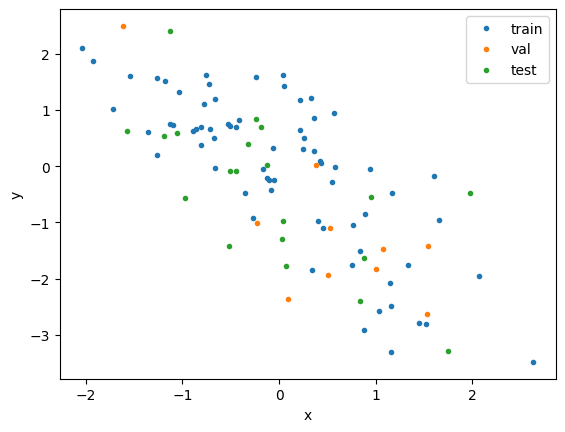

In [4]:
data_names = ['train', 'val', 'test']
for idata in range(len(data_names)):
    data_name = data_names[idata]
    X, y = D[idata]
    plt.plot(X, y, '.', label=data_name)
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.show()

The goal of this section is to write a series of functions to minimise the training RSS $${\rm RSS} = \sum_{i=1}^n (f(x_i)-y_i)^2$$ of a linear prediction model, $f(x) = \hat \beta_0 +\hat \beta_1 x \approx {\rm E}(Y|X=x)$, with gradient descent updates
$$ \beta^{(t+1)} \gets \beta^{(t)} - \eta \nabla_\beta {\rm RSS}(\beta^{(t)})$$
where $\eta=0.001$ is the learning rate, $\beta^{(0)}$ is a random initial guess, and $t=1, \dots, 100$ the number of epochs.


We write three extra functions that:
- compute the gradient of $f$, $\nabla f(\beta) = \tilde X$
- compute the RSS of $f$ on a given data set, and 
- compute the gradient of the RSS, $\nabla {\rm RSS}(\beta) = -2({\bf X}^T{\bf y} - {\bf X}^T{\bf X} \beta)$ on the given data set.

In [5]:
def grad_f(X, beta):
    tildeX = np.concatenate((np.ones([len(X), 1]), X), axis = 1)
    return tildeX

def RSS(train, beta):
    X, y = train
    haty = linear_model(X, beta)
    return np.sum((y-haty)**2)

def grad_RSS(train, beta):
    X, y = train
    haty = linear_model(X, beta)
    res = (y - haty).reshape(-1, 1)
    gf = grad_f(X, beta)
    return - 2 * np.sum(res * gf, axis = 0)

print(f"grad_f(D[0][0], beta)[:3] = {grad_f(D[0][0], beta)[:3]}")
print(f"RSS(D[0], beta) = {RSS(D[0], beta)}")
print(f"grad_RSS(D[0], beta) = {grad_RSS(D[0], beta)[:3]}")



grad_f(D[0][0], beta)[:3] = [[1.         1.15574248]
 [1.         0.84294088]
 [1.         0.94199674]]
RSS(D[0], beta) = 52.63225356292657
grad_RSS(D[0], beta) = [ 4.15814312 11.18916089]


We now have all the elements needed to write the training loop:
- the training data set (`D[0]`)
- the model (`linear_model`)
- the objective function (`RSS`)
- the gradient of the objective function (`grad_RSS`), 
- the loop parameters ($\eta=0.001$, $\beta_i^{(0)} \sim {\rm Uniform}[0, 1]$, $T=100$)

To check if the model is learning, we store the values of the objective at each iteration and plot them at the end.

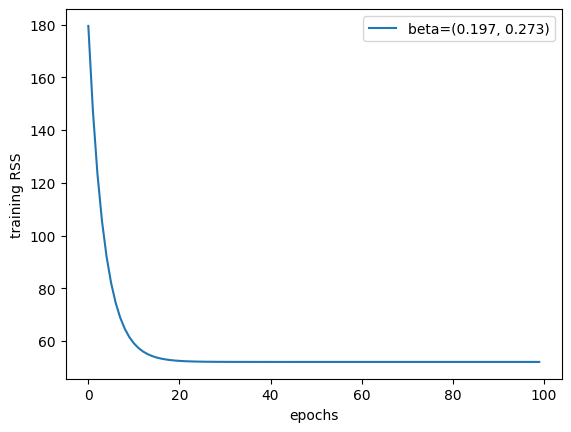

In [ ]:
T = 100 # epochs
eta = 0.001 # training steps
train = D[0]

beta0 = np.random.rand(len(beta))

obj = []
beta = beta0
for t in range(T):
    obj.append(RSS(train, beta))
    grad = grad_RSS(train, beta)
    beta  = beta - eta * grad

plt.plot(obj, label=f'beta=({beta0[0]:.3f}, {beta0[1]:.3f})')
plt.xlabel('epochs')
plt.ylabel('training RSS')
plt.legend()
plt.show()
    

## KNN


KNN is powerful, intuitive, and flexible.
You can use it for regression and classification. 
It is often called a transductive algorithm because the predictions are obtained directly from the training data.
The algorithm hyperparameter, $K$, should be fixed according to the performance on a validation dataset.

The goal of this section is to implement a regression KNN algorithm to predict the value of houses in the "Boston" data set.

Load the Boston data set with Pandas.

In [7]:
file = "bostonDataAnalysis202627.txt"
data = pd.read_csv(file,  sep='\t', header=0)
print(f'attributes: {data.columns}')
print(f'first object: {data.values[0]}')
print(f'size of the data set: |D| = {len(data.values)}')

attributes: Index(['OBS.', 'TOWN', 'TOWN.1', 'TRACT', 'LON', 'LAT', 'MEDV', 'CMEDV',
       'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT'],
      dtype='str')
first object: [1 'Nahant' 0 2011 -70.955 42.255 24.0 24.0 0.00632 18.0 2.31 0 0.538
 6.575 65.2 4.09 1 296 15.3 396.9 4.98]


size of the data set: |D| = 506


Neglect all nominal features (`TOWN`, `TOWN.1`), use either `MEDV` or `CMEDV` as response, and ignore the other one. `TRACT` is kept among the predictors as a numeric proxy for location, alongside `LON`/`LAT`.

In [8]:
# create the labels
select = ['MEDV']
y = data[select[0]].values
# create the attributes
select = ['TRACT', 'LON', 'LAT', 'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT'] 
X = np.concatenate([data[s].values.reshape(-1, 1) for s in select], axis = 1)
print(f'X.shape = {X.shape}, y.shape = {y.shape}')

X.shape = (506, 16), y.shape = (506,)


Split the data using `split_dataset` above

In [36]:
D = split_dataset((X, y), [.6, .2, .2])
print(f"|D_train| = {len(D[0][0])}, |D_val|={len(D[1][0])}, |D_test| = {len(D[2][0])} ")

|D_train| = 303, |D_val|=101, |D_test| = 102 


Implement a function that returns the *Euclidean distance* between $x$ and all the elements of a data set, i.e
$${\rm dist}(x, D=\{x_i\}_{i=1}^n) = (\| x - x_1 \|, \dots, \|x-x_n\|)$$
Use `p_norm` with $v=x-x'$ and $p=2$ to compute the distance between two objects.

In [35]:
def dist(x, D):
    return [p_norm(x - xi, 2) for xi in D]

x=D[0][0][0]
Xtrain = D[0][0]
print(f'np.mean(dist(x, Xtrain)) = {np.mean(dist(x, Xtrain)):.3f}')
print(f'dist(x, Xtrain)[0] = {dist(x, Xtrain)[0]}')

NameError: name 'p_norm' is not defined

Try to understand the meaning of the outputs above.
Then write a function that returns the index of the $K$ neighbours of $x$ in $D=\{x_i\}_{i=1}^n$.
Use `np.argsort(v)` to obtain the index of the elements of a vector in increasing order. 

In [11]:
def neighbours(x, D, K):
    dists = dist(x, D)
    n = np.argsort(dists)[:K]
    return n
K = 5
print(f'neighbours(x, Xtrain, K) = {neighbours(x, Xtrain, K)}')

neighbours(x, Xtrain, K) = [  0 221 107 198  42]


Write a function that returns the KNN predictions, given a test point, $x$, the training data, $D = \{(x_i, y_i)\}_{i=1}^n$, and $K$.

In [12]:
def knn_regressor(x, D, K):
    Xtrain, ytrain = D
    n = neighbours(x, Xtrain, K)
    return np.mean([ytrain[i] for i in n])

Dtrain = D[0]
Xtest, ytest = D[2]
xtest = Xtest[0]
haty = knn_regressor(xtest, Dtrain, K)
print(f'y = {ytest[0]:.3f}, haty = {haty:.3f}')

y = 19.400, haty = 22.720


Plot the KNN prediction versus the true values for all test objects and report the RSS in the legend.

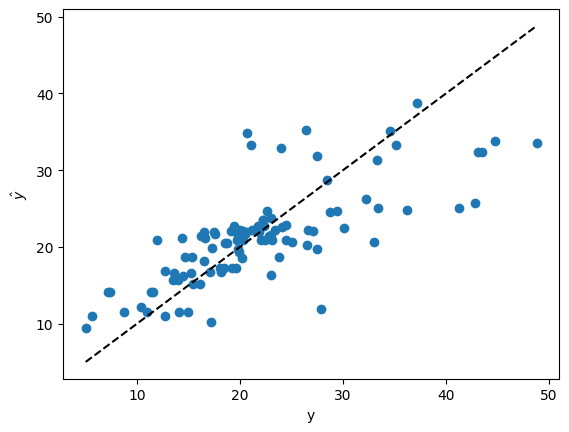

In [13]:
haty = np.array([knn_regressor(x, Dtrain, K) for x in Xtest])
y = np.array(ytest)
rss = np.sum((haty-y)**2)
plt.scatter(y, haty, label=f'RSS={rss:.3f}')
plt.plot([min(y), max(y)], [min(y), max(y)], 'k--')
plt.xlabel('y')
plt.ylabel('$\\hat y$')
plt.show()

## Exercises

You must complete the exercises below before attempting this week's Moodle quiz. Write your answers and your code in the dedicated cells below the questions.

### Q1

Check that choosing different initial values, $\beta^{(0)} \sim {\rm Uniform}([0, 1]^2)$, in the RSS minimisation for a linear model does not change the optimal value. In particular,
- Regenerate the random data set using a true parameter defined as $\beta_i = \frac{1}{i + 1}$ and 1000 random points (keep the same ratio)
- Reduce the learning rate to $\eta=0.0001$ and the number of epochs to $T=50$.
- Plot the RSS as a function of the number of iterations for 10 different values of $\beta^{(0)}$ on the same figure. Print the initial value of each run in the legend.

Explain why this is not a surprising result.

|D_train| = 700, |D_val| = 100, |D_test| = 200
Run 1: initial beta = [0.51684189 0.12956055], final beta = [ 0.16087    -1.30931313], final RSS = 682.760659
Run 2: initial beta = [0.21867731 0.20009009], final beta = [ 0.16071261 -1.30926902], final RSS = 682.760692
Run 3: initial beta = [0.29623448 0.0955942 ], final beta = [ 0.16075243 -1.30933911], final RSS = 682.760601
Run 4: initial beta = [0.85756297 0.81084002], final beta = [ 0.16105973 -1.30884521], final RSS = 682.761512
Run 5: initial beta = [0.3222625  0.97138759], final beta = [ 0.16077761 -1.30874293], final RSS = 682.761621
Run 6: initial beta = [0.13628602 0.0111937 ], final beta = [ 0.16066641 -1.3093986 ], final RSS = 682.760521
Run 7: initial beta = [0.28758488 0.75335362], final beta = [ 0.16075637 -1.30889172], final RSS = 682.761319
Run 8: initial beta = [0.34703685 0.39165887], final beta = [ 0.16078324 -1.30913702], final RSS = 682.760896
Run 9: initial beta = [0.29480615 0.6138226 ], final beta = [ 0.1607584  

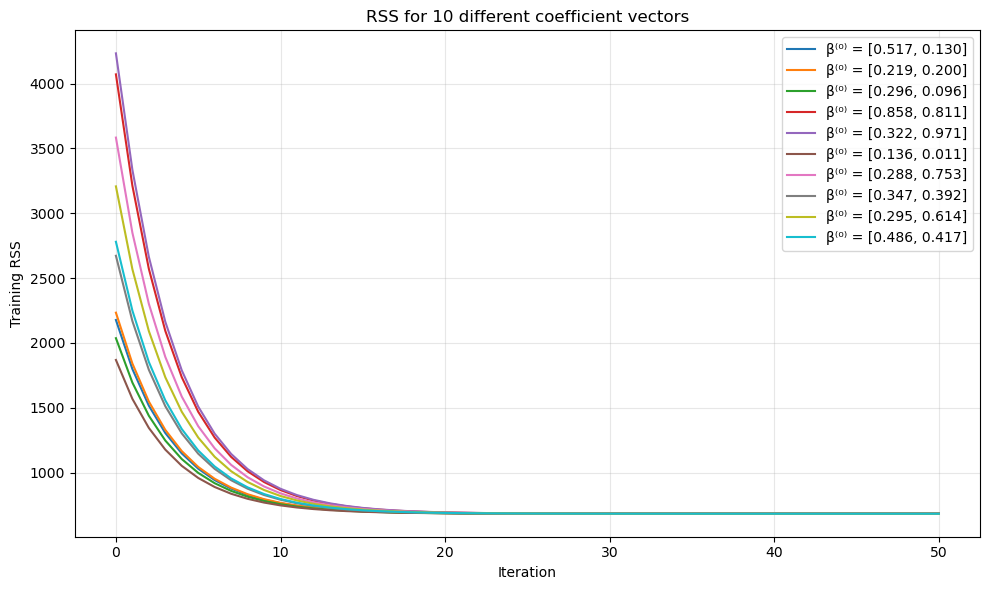

<Figure size 640x480 with 0 Axes>

In [ ]:
# write your code here

def linear_model(X, beta):
    tildeX = np.concatenate((np.ones([len(X), 1]), X), axis = 1)
    return tildeX @ beta

def split_dataset(D, ratio):
    X, y = D
    reshuffle = np.random.choice(len(X), len(X), replace=False)
    nratio = [int(np.floor(r * len(X))) for r in ratio]
    Xtrain, ytrain = [[s[i] for i in reshuffle[:nratio[0]]] for s in D]
    Xval, yval = [[s[i] for i in reshuffle[nratio[0]:nratio[0] + nratio[1]]] for s in D]
    Xtest, ytest = [[s[i] for i in reshuffle[nratio[0] + nratio[1]:]] for s in D]
    return (Xtrain, ytrain), (Xval, yval), (Xtest, ytest)

n_all = 1000 # points
d = 1
ratio = [.7, .1, .2]
X = np.random.randn(n_all, d)
beta_true = np.array([1 / (i + 1) for i in range(d + 1)])
y = linear_model(X, beta) + np.random.randn(len(X))
D = split_dataset((X, y), ratio)
print(
    f"|D_train| = {len(D[0][0])}, "
    f"|D_val| = {len(D[1][0])}, "
    f"|D_test| = {len(D[2][0])}"
)


def grad_f(X, beta):
    tildeX = np.concatenate((np.ones([len(X), 1]), X), axis = 1)
    return tildeX

def RSS(train, beta):
    X, y = train
    haty = linear_model(X, beta)
    return np.sum((y-haty)**2)

def grad_RSS(train, beta):
    X, y = train
    haty = linear_model(X, beta)
    res = (y - haty).reshape(-1, 1)
    gf = grad_f(X, beta)
    return - 2 * np.sum(res * gf, axis = 0)


T = 50 # epochs
eta = 0.0001 # training steps

train = (np.asarray(D[0][0]), np.asarray(D[0][1]))
plt.figure(figsize=(10, 6))


# 10 runs
for run in range(10):
    beta_initial = np.random.uniform(0, 1, size=d + 1)
    beta = beta_initial.copy()
    rss_history = [RSS(train, beta)]

    for epoch in range(T):
        beta = beta - eta * grad_RSS(train, beta)
        rss_history.append(RSS(train, beta))

    label = (
        f"β⁽⁰⁾ = [{beta_initial[0]:.3f}, "
        f"{beta_initial[1]:.3f}]"
    )

    plt.plot(range(T + 1), rss_history, label=label)

    print(
        f"Run {run + 1}: "
        f"initial beta = {beta_initial}, "
        f"final beta = {beta}, "
        f"final RSS = {rss_history[-1]:.6f}"
    )

plt.xlabel("Iteration")
plt.ylabel("Training RSS")
plt.title("RSS for 10 different coefficient vectors")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('Q1_plot.pdf')
plt.show()




Choosing different initial values in this run did not change the optimal value after 50 iterations, this isn't surprising as the data is generated only once same, meaning that each run uses the same data and learning steps.  

### Q2

Compare KNN and linear regression on the Boston data set. The linear regression model should be trained using GD as in Q1. You may need to adjust the training parameters to guarantee the convergence of the gradient iterates.

To make the algorithm more stable, normalise the predictors using the following function.

Which is the best algorithm to solve the prediction task? Comment on your results.

In [15]:
def normalize(X, eps = 0.001):
    X  = np.array([(X[:, i] - np.mean(X[:, i]))/(eps + np.std(X[:, i])) for i in range(len(X[0]))]).T
    return X

attributes: Index(['OBS.', 'TOWN', 'TOWN.1', 'TRACT', 'LON', 'LAT', 'MEDV', 'CMEDV',
       'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT'],
      dtype='object')
first object: [1 'Nahant' 0 2011 -70.955 42.255 24.0 24.0 0.00632 18.0 2.31 0 0.538
 6.575 65.2 4.09 1 296 15.3 396.9 4.98]
size of the data set: |D| = 506
p_norm(v, 0) = 3.000
p_norm(v, 1) = 6.000
p_norm(v, 2) = 3.742
X.shape = (506, 16), y.shape = (506,)
|D_train| = 303, |D_val|=101, |D_test| = 102 
np.mean(dist(x, Xtrain)) = 2209.581
dist(x, Xtrain)[0] = 0.0
neighbours(x, Xtrain, K) = [  0  62 301 289 160]
y = 0.871, haty = 0.711


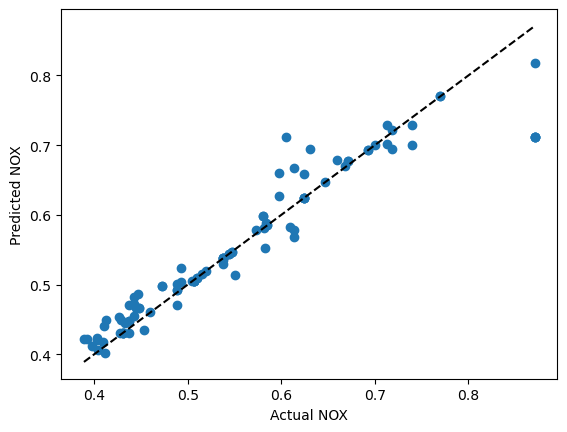

In [58]:
# KNN:

file = "bostonDataAnalysis202627.txt"
data = pd.read_csv(file,  sep='\t', header=0)
print(f'attributes: {data.columns}')
print(f'first object: {data.values[0]}')
print(f'size of the data set: |D| = {len(data.values)}')

def p_norm(v, p):
    n = 0
    for vi in v:
        n = n + np.power(abs(vi), p)
    if p: 
        return np.power(n, 1/p)
    else:
        return n

v = [1, 2, 3]
print(f'p_norm(v, 0) = {p_norm(v, 0):.3f}')
print(f'p_norm(v, 1) = {p_norm(v, 1):.3f}')
print(f'p_norm(v, 2) = {p_norm(v, 2):.3f}')

select = ['NOX']
y = data[select[0]].values
# create the attributes
select = ['TRACT', 'LON', 'LAT', 'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT'] 
X = np.concatenate([data[s].values.reshape(-1, 1) for s in select], axis = 1)
print(f'X.shape = {X.shape}, y.shape = {y.shape}')

# Split the data
D = split_dataset((X, y), [.6, .2, .2])
print(f"|D_train| = {len(D[0][0])}, |D_val|={len(D[1][0])}, |D_test| = {len(D[2][0])} ")

def dist(x, D):
    return [p_norm(x - xi, 2) for xi in D]

x=D[0][0][0]
Xtrain = D[0][0]
print(f'np.mean(dist(x, Xtrain)) = {np.mean(dist(x, Xtrain)):.3f}')
print(f'dist(x, Xtrain)[0] = {dist(x, Xtrain)[0]}')

def neighbours(x, D, K):
    dists = dist(x, D)
    n = np.argsort(dists)[:K]
    return n
K = 5
print(f'neighbours(x, Xtrain, K) = {neighbours(x, Xtrain, K)}')

def knn_regressor(x, D, K):
    Xtrain, ytrain = D
    n = neighbours(x, Xtrain, K)
    return np.mean([ytrain[i] for i in n])

Dtrain = D[0]
Xtest, ytest = D[2]
xtest = Xtest[0]
haty = knn_regressor(xtest, Dtrain, K)
print(f'y = {ytest[0]:.3f}, haty = {haty:.3f}')

def normalize(X, eps = 0.001):
    X  = np.array([(X[:, i] - np.mean(X[:, i]))/(eps + np.std(X[:, i])) for i in range(len(X[0]))]).T
    return X

haty = np.array([knn_regressor(x, Dtrain, K) for x in Xtest])
y = np.array(ytest)
rss = np.sum((haty-y)**2)
plt.scatter(y, haty, label=f'RSS={rss:.3f}')
plt.plot([min(y), max(y)], [min(y), max(y)], 'k--')
plt.xlabel(f"Actual NOX")
plt.ylabel(f"Predicted NOX")
plt.show()


Excluded columns: ['TOWN']
Target: NOX
X shape: (506, 19) | y shape: (506,)
Coefficients: [ 0.55846864 -0.01564085  0.00199333 -0.0172531   0.01652486 -0.02279298
 -0.02856678  0.00934717 -0.00469879  0.00066067  0.03194117  0.00645656
  0.00057646  0.01755332 -0.04769961  0.00930722  0.013857   -0.03781426
 -0.00257443 -0.00152946]
Final gradient norm: 1e-06
train: MSE=0.003, RMSE=0.053
val: MSE=0.003, RMSE=0.050
test: MSE=0.002, RMSE=0.047


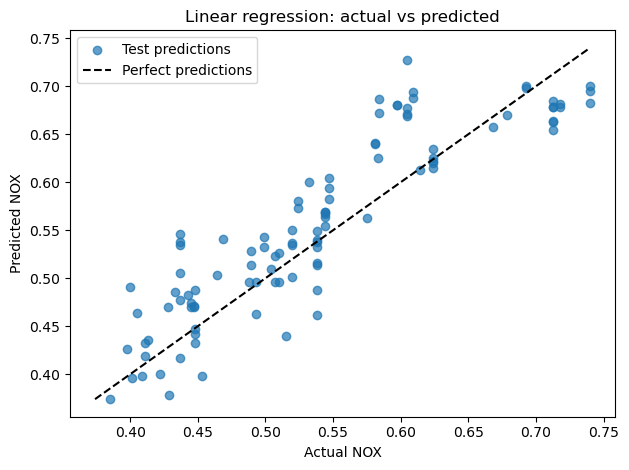

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("bostonDataAnalysis202627.txt", sep="\t", header = 0)
data.columns = data.columns.str.strip()
target_idx = 12  # 13th column in the original table
target_col = data.columns[target_idx]

y = pd.to_numeric(data.iloc[:, target_idx], errors="raise").to_numpy(float)
predictors = data.drop(columns=[target_col])
numeric = predictors.apply(pd.to_numeric, errors="coerce")

# Exclude columns containing text or missing values
valid = numeric.notna().all()
print("Excluded columns:", predictors.columns[~valid].tolist())
X = numeric.loc[:, valid].to_numpy(float)
print("Target:", target_col)
print("X shape:", X.shape, "| y shape:", y.shape)


idx = np.random.default_rng(42).permutation(len(X))
tr, va, te = np.split(idx, (np.array([.7, .8]) * len(X)).astype(int))

# Normalise predictors using training 
mu, sd = X[tr].mean(0), X[tr].std(0)
X = (X - mu) / np.where(sd == 0, 1, sd)
X = np.column_stack((np.ones(len(X)), X))

# Train using gradient descent
A, b = X[tr], y[tr]
beta = np.zeros(X.shape[1])
lr = len(A) / (2 * np.linalg.norm(A, 2) ** 2)

for _ in range(100_000):
    grad = 2 * A.T @ (A @ beta - b) / len(A)
    if np.linalg.norm(grad) < 1e-6:
        break
    beta -= lr * grad

print("Coefficients:", beta)
print(f"Final gradient norm: {np.linalg.norm(grad):.3g}")

# Evaluate
for name, i in [("train", tr), ("val", va), ("test", te)]:
    mse = np.mean((X[i] @ beta - y[i]) ** 2)
    print(f"{name}: MSE={mse:.3f}, RMSE={np.sqrt(mse):.3f}")

y_pred = X[te] @ beta
lo = min(y[te].min(), y_pred.min())
hi = max(y[te].max(), y_pred.max())

plt.scatter(y[te], y_pred, alpha=.7, label="Test predictions")
plt.plot([lo, hi], [lo, hi], "k--", label="Perfect predictions")
plt.xlabel(f"Actual {target_col}")
plt.ylabel(f"Predicted {target_col}")
plt.title("Linear regression: actual vs predicted")
plt.legend()
plt.tight_layout()
plt.show()

For the linear regression model I chose to use the NOX column as it had a medium-level of variation.
For KNN I chose to use the NOX column also and compare the results.

Conclusion: 

KNN has the highest number of perfect predictions, with predictions being as close to the , whereas the Linear Regression model has more variation in the results, and a lower number of perfect predictions.

